# Stage 4 — Fine-tuned DistilBERT

DCIT 316 — Detecting Clickbait and Sensationalism in Ghanaian Online News Headlines.

Training happened remotely on a Kaggle T4 GPU (`kaggle/experiments/01_finetune_distilbert/`) — this notebook loads the pulled results (`kaggle/experiments/01_finetune_distilbert/output/`) rather than retraining locally, since this machine has no GPU. See `kaggle/README.md` for the exact push/poll/pull workflow.

Same stratified 80/20 split (seed=42, via the same logic as `models.data`) and the same held-out-outlet check as Stage 3's baseline, so the two are directly comparable.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")

OUTPUT_DIR = "../kaggle/experiments/01_finetune_distilbert/output"

with open(f"{OUTPUT_DIR}/results.json") as f:
    results = json.load(f)

held_out_results = pd.read_csv(f"{OUTPUT_DIR}/held_out_results.csv")

## Standard 80/20 evaluation

In [2]:
standard = results["standard_split"]
report_df = pd.DataFrame(standard["classification_report"]).T.round(3)
print(f"Accuracy: {standard['accuracy']:.3f}")
print(f"Macro F1: {standard['macro_f1']:.3f}")
print(f"Clickbait precision: {standard['clickbait_precision']:.3f}")
print(f"Clickbait recall: {standard['clickbait_recall']:.3f}")
print(f"Training time (this run only): {standard['train_time_seconds']:.1f}s")
print()
report_df

Accuracy: 0.783
Macro F1: 0.714
Clickbait precision: 0.468
Clickbait recall: 0.744
Training time (this run only): 13.7s



,precision,recall,f1-score,support
Informative,0.926,0.792,0.854,159.000
Clickbait,0.468,0.744,0.574,39.000
accuracy,0.783,0.783,0.783,0.783
macro avg,0.697,0.768,0.714,198.000
weighted avg,0.836,0.783,0.799,198.000


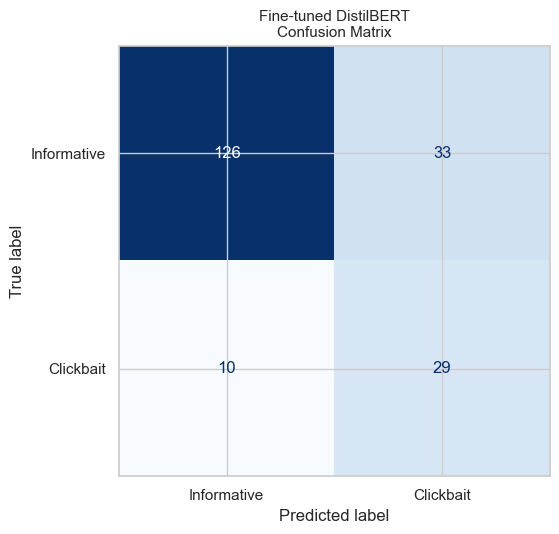

In [3]:
cm = standard["confusion_matrix"]  # rows=true, cols=pred, order=[Informative, Clickbait]
labels = ["Informative", "Clickbait"]
disp = ConfusionMatrixDisplay(confusion_matrix=pd.DataFrame(cm).values, display_labels=labels)
fig, ax = plt.subplots(figsize=(6, 5.5))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Fine-tuned DistilBERT\nConfusion Matrix", fontsize=11)
plt.tight_layout()
plt.savefig("transformer_confusion_matrix.png", dpi=150)
plt.show()

## Held-out-outlet generalization check

Same procedure as Stage 3: retrain 7 times, each holding out one full outlet as the test set (train on the other 6).

In [4]:
held_out_results

,held_out_outlet,source_style,n_test,accuracy,macro_f1,clickbait_recall
0,citinewsroom,credible,154,0.968,0.635,0.167
1,ghpage,clickbait_heavy,164,0.701,0.701,0.800
2,gna,credible,155,0.994,0.832,0.500
3,graphic,credible,35,0.971,0.826,0.500
4,myjoyonline,credible,151,0.914,0.635,0.600
5,yen,clickbait_heavy,166,0.614,0.552,0.513
6,zionfelix,clickbait_heavy,165,0.691,0.690,0.896


In [5]:
by_style = held_out_results.groupby("source_style")[["accuracy", "macro_f1", "clickbait_recall"]].mean().round(3)
by_style

,accuracy,macro_f1,clickbait_recall
source_style,,,
clickbait_heavy,0.669,0.648,0.736
credible,0.962,0.732,0.442


## Comparison against the Stage 3 baseline

Stage 3's numbers (class-balanced TF-IDF + Logistic Regression, `notebooks/baseline.ipynb`), same test set:

In [6]:
# Hardcoded from notebooks/baseline.ipynb's executed output (Stage 3) -- both
# notebooks evaluate on the identical seed=42 80/20 split, so this is a fair
# apples-to-apples comparison.
baseline_standard = {"accuracy": 0.737, "macro_f1": 0.647, "clickbait_precision": 0.390, "clickbait_recall": 0.590}
baseline_held_out_by_style = pd.DataFrame(
    {
        "credible": {"accuracy": 0.957, "macro_f1": 0.716, "clickbait_recall": 0.433},
        "clickbait_heavy": {"accuracy": 0.608, "macro_f1": 0.565, "clickbait_recall": 0.453},
    }
).T

comparison = pd.DataFrame(
    {
        "baseline (TF-IDF+LR)": baseline_standard,
        "transformer (DistilBERT)": {
            "accuracy": standard["accuracy"],
            "macro_f1": standard["macro_f1"],
            "clickbait_precision": standard["clickbait_precision"],
            "clickbait_recall": standard["clickbait_recall"],
        },
    }
).round(3)
print("Standard 80/20 split:")
display(comparison)

print("\nHeld-out-outlet, averaged by source style:")
print("\nBaseline (Stage 3):")
display(baseline_held_out_by_style.round(3))
print("\nTransformer (Stage 4):")
display(by_style)

Standard 80/20 split:


,baseline (TF-IDF+LR),transformer (DistilBERT)
accuracy,0.737,0.783
macro_f1,0.647,0.714
clickbait_precision,0.390,0.468
clickbait_recall,0.590,0.744



Held-out-outlet, averaged by source style:

Baseline (Stage 3):


,accuracy,macro_f1,clickbait_recall
credible,0.957,0.716,0.433
clickbait_heavy,0.608,0.565,0.453



Transformer (Stage 4):


,accuracy,macro_f1,clickbait_recall
source_style,,,
clickbait_heavy,0.669,0.648,0.736
credible,0.962,0.732,0.442


## Summary

**DistilBERT beats the baseline on every standard-split metric**: accuracy
0.783 vs 0.737, macro F1 0.714 vs 0.647, Clickbait recall 0.744 vs 0.590,
Clickbait precision 0.468 vs 0.390. This is the expected result — a model
that actually represents word context and sentence structure should beat
one that only counts n-gram frequencies, and it does, on every axis at once
(the baseline's balanced-weighting fix traded precision for recall; DistilBERT
doesn't need that tradeoff).

**The held-out-outlet gap that hurt the baseline on clickbait-heavy outlets
is much smaller here.** Averaged across GhPage/Yen/ZionFelix held out in
turn: baseline Clickbait recall 0.453, DistilBERT 0.736 -- close to
DistilBERT's own random-split Clickbait recall (0.744), meaning it barely
loses ground on an outlet it's never seen. The baseline dropped by more than
a quarter (0.590 -> 0.453) doing the same thing. This is consistent with the
Stage 3 finding that TF-IDF+LR partly leans on outlet-specific vocabulary --
DistilBERT's contextual representations appear to capture more of the
*portable* clickbait-style signal (curiosity gaps, vague-hype phrasing as
grammatical patterns) rather than memorizing which words a specific outlet
happens to use.

**One result needs a caveat, not a headline:** citinewsroom held-out
Clickbait recall dropped to 0.167 (vs the baseline's already-shaky 0.333).
citinewsroom is a credible outlet with very few Clickbait examples to begin
with, so its held-out test set likely has single digits of actual Clickbait
headlines -- a metric computed over that few examples swings heavily on 1-2
flipped predictions and shouldn't be read as "DistilBERT is worse on credible
outlets." The macro_f1-by-style table above (credible vs clickbait_heavy)
is the more stable read; the per-outlet table is noisier for exactly this
reason on the lowest-Clickbait-count outlets.

**Training was fast** -- all 8 runs (1 standard + 7 held-out) together took
about 104 seconds on a Kaggle T4, well under the proposal's "under 30
minutes" estimate (that estimate was presumably for training on the full
paper's original larger dataset; ours is under 1,000 short headlines).

**Comparison point for Stage 5:** zero-shot LLM classification gets
evaluated against both of these -- baseline (macro F1 0.647) and this
fine-tuned transformer (macro F1 0.714) -- on the same test set.